**Customer Value And Retention**

In [6]:
from google.colab import files
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
uploaded = files.upload()

Saving customer_master.csv to customer_master (1).csv
Saving dataset_statistics.csv to dataset_statistics (1).csv
Saving ecommerce_sales_customer_analytics_150k.csv to ecommerce_sales_customer_analytics_150k (1).csv
Saving order_items.csv to order_items (1).csv
Saving product_catalog.csv to product_catalog (1).csv


In [8]:
customers = pd.read_csv("customer_master.csv")
dataset_stats = pd.read_csv("dataset_statistics.csv")
sales = pd.read_csv("ecommerce_sales_customer_analytics_150k.csv")
order_items = pd.read_csv("order_items.csv")
products = pd.read_csv("product_catalog.csv")

In [9]:
sales["order_date"] = pd.to_datetime(
    sales["order_date"],
    format="mixed",
    dayfirst=True,
    errors="coerce")

In [10]:
print("Invalid dates:", sales["order_date"].isna().sum())
print("Date range:", sales["order_date"].min(), "to", sales["order_date"].max())

Invalid dates: 0
Date range: 2021-01-01 00:00:00 to 2025-12-31 00:00:00


In [11]:
sales["currency"].value_counts()

,count
currency,
USD,82600
GBP,20235
EUR,11593
CAD,7015
AUD,6794
INR,5707
AED,4172


In [12]:
sales.groupby("currency")["net_sales"].agg(
    orders="count",
    total_net_sales="sum",
    average_net_sales="mean"
).sort_values("orders", ascending=False)

,orders,total_net_sales,average_net_sales
currency,,,
USD,82600,1.022301e+08,1237.652438
GBP,20235,2.796320e+07,1381.922451
EUR,11593,1.604417e+07,1383.953412
CAD,7015,9.198848e+06,1311.311259
AUD,6794,8.813691e+06,1297.275612
INR,5707,7.718287e+06,1352.424615
AED,4172,5.165973e+06,1238.248660


In [13]:
customer_currency_count = sales.groupby("customer_id")["currency"].nunique()

print("Customers with 1 currency:", (customer_currency_count == 1).sum())
print("Customers with multiple currencies:", (customer_currency_count > 1).sum())

Customers with 1 currency: 24911
Customers with multiple currencies: 0


In [14]:
customer_summary = sales.groupby("customer_id").agg(
    currency=("currency", "first"),
    orders=("order_id", "nunique"),
    revenue=("net_sales", "sum"),
    profit=("profit", "sum"),
    quantity=("quantity", "sum"),
    first_order_date=("order_date", "min"),
    last_order_date=("order_date", "max")
).reset_index()

In [15]:
customer_summary.head()

,customer_id,currency,orders,revenue,profit,quantity,first_order_date,last_order_date
0,CUST-000001,AED,9,9924.84,3894.40,40,2021-02-09,2025-12-25
1,CUST-000002,EUR,10,18138.96,9138.59,54,2021-04-27,2025-03-24
2,CUST-000003,EUR,7,7798.59,3871.98,27,2021-05-21,2025-06-05
3,CUST-000004,USD,7,11218.95,3745.70,58,2024-05-03,2025-11-07
4,CUST-000005,USD,8,10063.97,4021.66,70,2021-06-14,2024-11-14


In [16]:
print("Customers In Summary:", customer_summary["customer_id"].nunique())
print("Missing Customer IDs:", customer_summary["customer_id"].isna().sum())
print("Currencies In Summary:", customer_summary["currency"].nunique())

Customers In Summary: 24911
Missing Customer IDs: 0
Currencies In Summary: 7


In [17]:
analysis_date = sales["order_date"].max() + pd.Timedelta(days=1)

print("Analysis date:", analysis_date)

Analysis date: 2026-01-01 00:00:00


In [18]:
customer_summary["recency"] = (
    analysis_date - customer_summary["last_order_date"]).dt.days

customer_summary["frequency"] = customer_summary["orders"]

customer_summary["monetary"] = customer_summary["revenue"]

In [19]:
customer_summary[
    ["customer_id", "currency", "recency", "frequency", "monetary"]
].head(10)

,customer_id,currency,recency,frequency,monetary
0,CUST-000001,AED,7,9,9924.84
1,CUST-000002,EUR,283,10,18138.96
2,CUST-000003,EUR,210,7,7798.59
3,CUST-000004,USD,55,7,11218.95
4,CUST-000005,USD,413,8,10063.97
5,CUST-000006,GBP,291,7,9284.89
6,CUST-000007,USD,468,4,7912.63
7,CUST-000008,USD,142,8,4938.79
8,CUST-000009,USD,477,4,2615.45
9,CUST-000010,EUR,72,4,9556.63


In [20]:
customer_summary["R_score"] = customer_summary.groupby("currency")["recency"].transform(
    lambda x: pd.qcut(x, 5, labels=[5, 4, 3, 2, 1])
)

customer_summary["F_score"] = customer_summary.groupby("currency")["frequency"].transform(
    lambda x: pd.qcut(
        x.rank(method="first"),
        5,
        labels=[1, 2, 3, 4, 5]
    )
)

customer_summary["M_score"] = customer_summary.groupby("currency")["monetary"].transform(
    lambda x: pd.qcut(x, 5, labels=[1, 2, 3, 4, 5])
)

In [21]:
customer_summary[
    [
        "customer_id",
        "currency",
        "recency",
        "frequency",
        "monetary",
        "R_score",
        "F_score",
        "M_score"
    ]
].head(10)

,customer_id,currency,recency,frequency,monetary,R_score,F_score,M_score
0,CUST-000001,AED,7,9,9924.84,5,5,5
1,CUST-000002,EUR,283,10,18138.96,3,5,5
2,CUST-000003,EUR,210,7,7798.59,3,4,3
3,CUST-000004,USD,55,7,11218.95,4,4,5
4,CUST-000005,USD,413,8,10063.97,2,5,5
5,CUST-000006,GBP,291,7,9284.89,2,4,4
6,CUST-000007,USD,468,4,7912.63,2,1,4
7,CUST-000008,USD,142,8,4938.79,3,5,2
8,CUST-000009,USD,477,4,2615.45,2,1,1
9,CUST-000010,EUR,72,4,9556.63,4,1,4


In [22]:
customer_summary["rfm_score"] = (
    customer_summary["R_score"].astype(str)
    + customer_summary["F_score"].astype(str)
    + customer_summary["M_score"].astype(str))

In [23]:
customer_summary[
    ["customer_id", "R_score", "F_score", "M_score", "rfm_score"]
].head(10)

,customer_id,R_score,F_score,M_score,rfm_score
0,CUST-000001,5,5,5,555
1,CUST-000002,3,5,5,355
2,CUST-000003,3,4,3,343
3,CUST-000004,4,4,5,445
4,CUST-000005,2,5,5,255
5,CUST-000006,2,4,4,244
6,CUST-000007,2,1,4,214
7,CUST-000008,3,5,2,352
8,CUST-000009,2,1,1,211
9,CUST-000010,4,1,4,414


In [24]:
def assign_rfm_segment(row):
    if row["R_score"] >= 4 and row["F_score"] >= 4 and row["M_score"] >= 4:
        return "Champions"

    elif row["R_score"] >= 3 and row["F_score"] >= 3:
        return "Loyal Customers"

    elif row["R_score"] <= 2 and row["F_score"] >= 3:
        return "At Risk"

    elif row["R_score"] >= 4 and row["F_score"] <= 2:
        return "New Customers"

    else:
        return "Low Engagement"


customer_summary["rfm_segment"] = customer_summary.apply(
    assign_rfm_segment,
    axis=1
)

In [25]:
customer_summary["rfm_segment"].value_counts()

,count
rfm_segment,
Low Engagement,7263
Loyal Customers,6655
At Risk,4410
Champions,3879
New Customers,2704


In [26]:
customer_summary["R_score"] = customer_summary["R_score"].astype(int)
customer_summary["F_score"] = customer_summary["F_score"].astype(int)
customer_summary["M_score"] = customer_summary["M_score"].astype(int)

In [27]:
customer_summary["customer_profit_margin"] = (
    customer_summary["profit"]
    / customer_summary["revenue"]
    * 100
)

In [28]:
rfm_summary = customer_summary.groupby("rfm_segment").agg(
    customers=("customer_id", "nunique"),
    orders=("orders", "sum"),
    average_orders=("orders", "mean"),
    average_recency=("recency", "mean"),
    average_frequency=("frequency", "mean"),
    average_monetary_score=("M_score", "mean"),
    average_profit_margin=("customer_profit_margin", "mean")
).reset_index()

rfm_summary["customer_share"] = (
    rfm_summary["customers"]
    / rfm_summary["customers"].sum()
    * 100
)

rfm_summary = rfm_summary.sort_values(
    "customers",
    ascending=False
).reset_index(drop=True)

rfm_summary

,rfm_segment,customers,orders,average_orders,average_recency,average_frequency,average_monetary_score,average_profit_margin,customer_share
0,Low Engagement,7263,23794,3.276057,571.299050,3.276057,1.930470,44.246711,29.155795
1,Loyal Customers,6655,43340,6.512397,132.380316,6.512397,3.254095,43.678980,26.715106
2,At Risk,4410,28640,6.494331,491.855556,6.494331,3.512245,43.619181,17.703023
3,Champions,3879,32470,8.370714,56.883733,8.370714,4.606600,42.310310,15.571434
4,New Customers,2704,9872,3.650888,62.528846,3.650888,2.105769,42.334124,10.854643


In [29]:
rfm_summary = rfm_summary.reset_index(drop=True)
rfm_summary

,rfm_segment,customers,orders,average_orders,average_recency,average_frequency,average_monetary_score,average_profit_margin,customer_share
0,Low Engagement,7263,23794,3.276057,571.299050,3.276057,1.930470,44.246711,29.155795
1,Loyal Customers,6655,43340,6.512397,132.380316,6.512397,3.254095,43.678980,26.715106
2,At Risk,4410,28640,6.494331,491.855556,6.494331,3.512245,43.619181,17.703023
3,Champions,3879,32470,8.370714,56.883733,8.370714,4.606600,42.310310,15.571434
4,New Customers,2704,9872,3.650888,62.528846,3.650888,2.105769,42.334124,10.854643


In [30]:
customer_summary.head()

,customer_id,currency,orders,revenue,profit,quantity,first_order_date,last_order_date,recency,frequency,monetary,R_score,F_score,M_score,rfm_score,rfm_segment,customer_profit_margin
0,CUST-000001,AED,9,9924.84,3894.40,40,2021-02-09,2025-12-25,7,9,9924.84,5,5,5,555,Champions,39.238920
1,CUST-000002,EUR,10,18138.96,9138.59,54,2021-04-27,2025-03-24,283,10,18138.96,3,5,5,355,Loyal Customers,50.381003
2,CUST-000003,EUR,7,7798.59,3871.98,27,2021-05-21,2025-06-05,210,7,7798.59,3,4,3,343,Loyal Customers,49.649744
3,CUST-000004,USD,7,11218.95,3745.70,58,2024-05-03,2025-11-07,55,7,11218.95,4,4,5,445,Champions,33.387260
4,CUST-000005,USD,8,10063.97,4021.66,70,2021-06-14,2024-11-14,413,8,10063.97,2,5,5,255,At Risk,39.960970


In [31]:
customer_summary.to_csv(
    "customer_rfm.csv",
    index=False)

In [32]:
customer_summary["cohort_month"] = (
    customer_summary["first_order_date"]
    .dt.to_period("M")
    .dt.to_timestamp())

In [33]:
customer_summary[
    ["customer_id", "first_order_date", "cohort_month"]
].head(10)

,customer_id,first_order_date,cohort_month
0,CUST-000001,2021-02-09,2021-02-01
1,CUST-000002,2021-04-27,2021-04-01
2,CUST-000003,2021-05-21,2021-05-01
3,CUST-000004,2024-05-03,2024-05-01
4,CUST-000005,2021-06-14,2021-06-01
5,CUST-000006,2021-09-07,2021-09-01
6,CUST-000007,2021-06-10,2021-06-01
7,CUST-000008,2021-05-25,2021-05-01
8,CUST-000009,2022-10-27,2022-10-01
9,CUST-000010,2022-02-14,2022-02-01


In [34]:
sales = sales.merge(
    customer_summary[["customer_id", "cohort_month"]],
    on="customer_id",
    how="left")

In [35]:
sales[
    ["customer_id", "order_date", "cohort_month"]
].head(10)

,customer_id,order_date,cohort_month
0,CUST-003102,2023-11-06,2021-08-01
1,CUST-003124,2025-12-24,2022-03-01
2,CUST-012496,2021-07-05,2021-07-01
3,CUST-023928,2023-01-21,2021-04-01
4,CUST-012730,2022-05-13,2022-05-01
5,CUST-021468,2021-02-10,2021-02-01
6,CUST-023734,2021-05-03,2021-05-01
7,CUST-020081,2022-10-13,2021-01-01
8,CUST-011921,2022-12-06,2021-06-01
9,CUST-016600,2023-09-19,2021-10-01


In [36]:
sales["order_month"] = (
    sales["order_date"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

sales["cohort_index"] = (
    (sales["order_month"].dt.year - sales["cohort_month"].dt.year) * 12
    + (sales["order_month"].dt.month - sales["cohort_month"].dt.month)
)

In [37]:
sales[
    ["customer_id", "cohort_month", "order_month", "cohort_index"]
].head(10)

,customer_id,cohort_month,order_month,cohort_index
0,CUST-003102,2021-08-01,2023-11-01,27
1,CUST-003124,2022-03-01,2025-12-01,45
2,CUST-012496,2021-07-01,2021-07-01,0
3,CUST-023928,2021-04-01,2023-01-01,21
4,CUST-012730,2022-05-01,2022-05-01,0
5,CUST-021468,2021-02-01,2021-02-01,0
6,CUST-023734,2021-05-01,2021-05-01,0
7,CUST-020081,2021-01-01,2022-10-01,21
8,CUST-011921,2021-06-01,2022-12-01,18
9,CUST-016600,2021-10-01,2023-09-01,23


In [38]:
cohort_activity = sales[
    ["customer_id", "cohort_month", "cohort_index"]
].drop_duplicates()

In [39]:
cohort_counts = cohort_activity.groupby(
    ["cohort_month", "cohort_index"]
)["customer_id"].nunique().reset_index()

In [40]:
cohort_counts.head(10)

,cohort_month,cohort_index,customer_id
0,2021-01-01,0,1824
1,2021-01-01,1,114
2,2021-01-01,2,142
3,2021-01-01,3,116
4,2021-01-01,4,150
5,2021-01-01,5,154
6,2021-01-01,6,142
7,2021-01-01,7,179
8,2021-01-01,8,158
9,2021-01-01,9,157


In [41]:
cohort_counts["cohort_size"] = cohort_counts.groupby("cohort_month")[
    "customer_id"
].transform("first")

cohort_counts["retention_rate"] = (
    cohort_counts["customer_id"] / cohort_counts["cohort_size"] * 100)

In [42]:
cohort_counts.head(10)

,cohort_month,cohort_index,customer_id,cohort_size,retention_rate
0,2021-01-01,0,1824,1824,100.000000
1,2021-01-01,1,114,1824,6.250000
2,2021-01-01,2,142,1824,7.785088
3,2021-01-01,3,116,1824,6.359649
4,2021-01-01,4,150,1824,8.223684
5,2021-01-01,5,154,1824,8.442982
6,2021-01-01,6,142,1824,7.785088
7,2021-01-01,7,179,1824,9.813596
8,2021-01-01,8,158,1824,8.662281
9,2021-01-01,9,157,1824,8.607456


In [43]:
retention_matrix = cohort_counts.pivot(
    index="cohort_month",
    columns="cohort_index",
    values="retention_rate")

In [44]:
retention_matrix.head()

cohort_index,0,1,2,3,4,5,6,7,8,9,...,50,51,52,53,54,55,56,57,58,59
cohort_month,,,,,,,,,,,,,,,,,,,,,
2021-01-01,100.0,6.250000,7.785088,6.359649,8.223684,8.442982,7.785088,9.813596,8.662281,8.607456,...,7.510965,7.949561,7.291667,8.936404,8.059211,9.210526,8.059211,8.826754,10.855263,12.609649
2021-02-01,100.0,8.148678,7.576841,8.434596,9.292352,8.506076,9.721229,8.791994,10.364546,11.365261,...,8.363117,8.934954,7.648320,7.576841,10.221587,9.435311,9.935668,11.222302,13.009292,NaN
2021-03-01,100.0,8.242950,6.941432,9.219089,7.917570,9.056399,8.731020,9.381779,12.472885,13.937093,...,7.537961,7.863341,7.429501,8.026030,7.104121,9.381779,13.503254,14.913232,NaN,NaN
2021-04-01,100.0,8.416834,8.617234,8.817635,9.084836,9.018036,8.884436,11.623246,12.491650,7.748831,...,7.147629,8.483634,8.750835,8.483634,8.684035,11.890448,14.028056,NaN,NaN,NaN
2021-05-01,100.0,8.372721,7.157326,9.655638,8.237677,8.845375,10.398379,14.247130,7.427414,6.347063,...,6.819716,10.465901,7.832546,8.372721,12.694126,12.761648,NaN,NaN,NaN,NaN


In [45]:
retention_12m = retention_matrix.iloc[:, :13]

In [46]:
retention_12m.head()

cohort_index,0,1,2,3,4,5,6,7,8,9,10,11,12
cohort_month,,,,,,,,,,,,,
2021-01-01,100.0,6.250000,7.785088,6.359649,8.223684,8.442982,7.785088,9.813596,8.662281,8.607456,10.416667,13.760965,7.620614
2021-02-01,100.0,8.148678,7.576841,8.434596,9.292352,8.506076,9.721229,8.791994,10.364546,11.365261,12.937813,7.147963,5.146533
2021-03-01,100.0,8.242950,6.941432,9.219089,7.917570,9.056399,8.731020,9.381779,12.472885,13.937093,6.507592,6.561822,7.592191
2021-04-01,100.0,8.416834,8.617234,8.817635,9.084836,9.018036,8.884436,11.623246,12.491650,7.748831,6.346025,8.817635,8.617234
2021-05-01,100.0,8.372721,7.157326,9.655638,8.237677,8.845375,10.398379,14.247130,7.427414,6.347063,8.440243,7.224848,8.575287


In [47]:
retention_12m.to_csv(
    "customer_cohort_retention.csv")

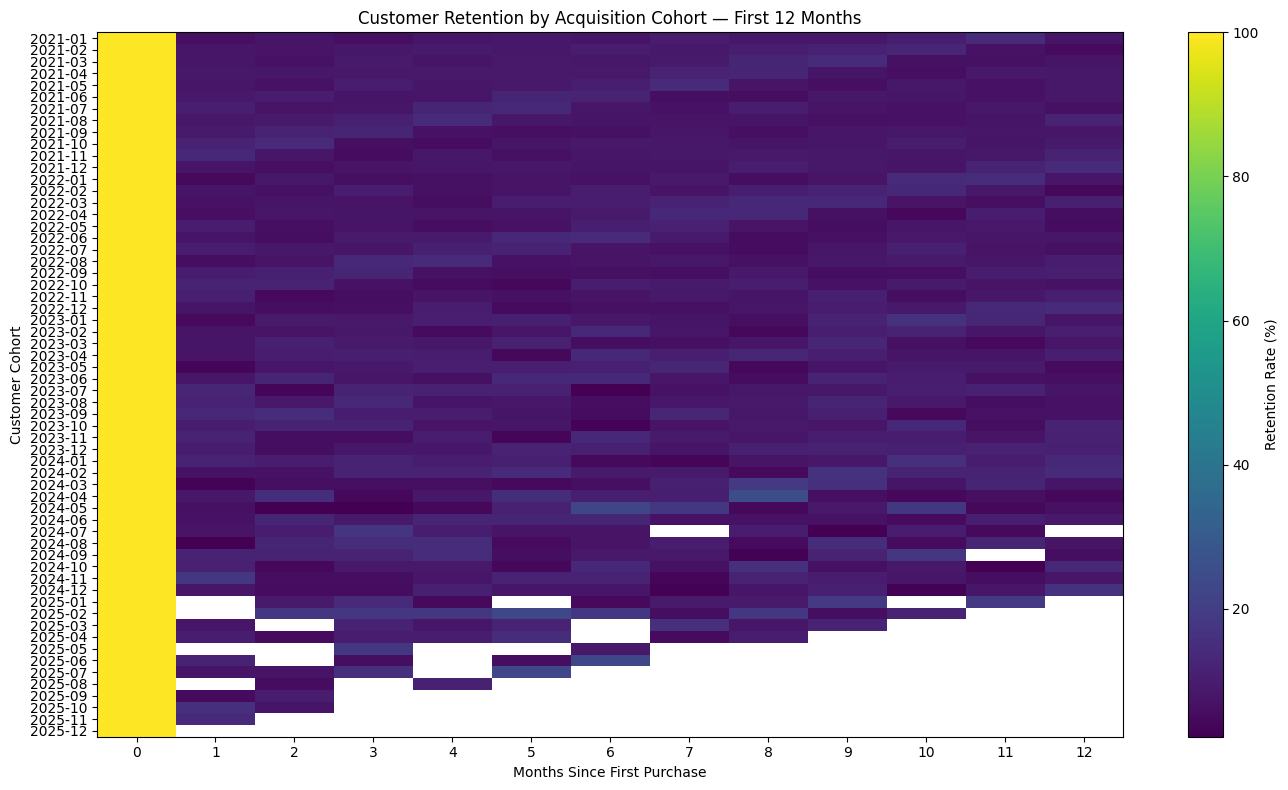

In [48]:
plt.figure(figsize=(14, 8))

plt.imshow(retention_12m, aspect="auto")

plt.colorbar(label="Retention Rate (%)")

plt.title("Customer Retention by Acquisition Cohort — First 12 Months")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Cohort")

plt.xticks(
    range(len(retention_12m.columns)),
    retention_12m.columns)

plt.yticks(
    range(len(retention_12m.index)),
    retention_12m.index.strftime("%Y-%m"))

plt.tight_layout()
plt.show()

**Commercial & Operations**

In [49]:
sales["discount_rate"] = (
    sales["discount_amount"] / sales["gross_sales"] * 100)

In [50]:
sales["discount_rate"].describe()

,discount_rate
count,138116.000000
mean,15.117085
std,12.287188
min,0.000000
25%,6.543998
50%,12.747787
75%,20.598256
max,60.019940


In [51]:
print("Discount Rates Below 0%:", (sales["discount_rate"] < 0).sum())
print("Discount Rates Above 100%:", (sales["discount_rate"] > 100).sum())

Discount Rates Below 0%: 0
Discount Rates Above 100%: 0


In [52]:
sales["discount_band"] = pd.qcut(
    sales["discount_rate"],4,
    labels=["Low", "Moderate", "High", "Very High"])

In [53]:
discount_analysis = sales.groupby("discount_band", observed=True).agg(
    orders=("order_id", "nunique"),
    average_discount=("discount_rate", "mean"),
    average_profit_margin=("profit_margin_percentage", "mean")
).reset_index()

In [54]:
discount_analysis

,discount_band,orders,average_discount,average_profit_margin
0,Low,34529,2.003747,53.131594
1,Moderate,34529,9.763720,49.380529
2,High,34529,16.143707,45.625681
3,Very High,34529,32.557167,32.126186


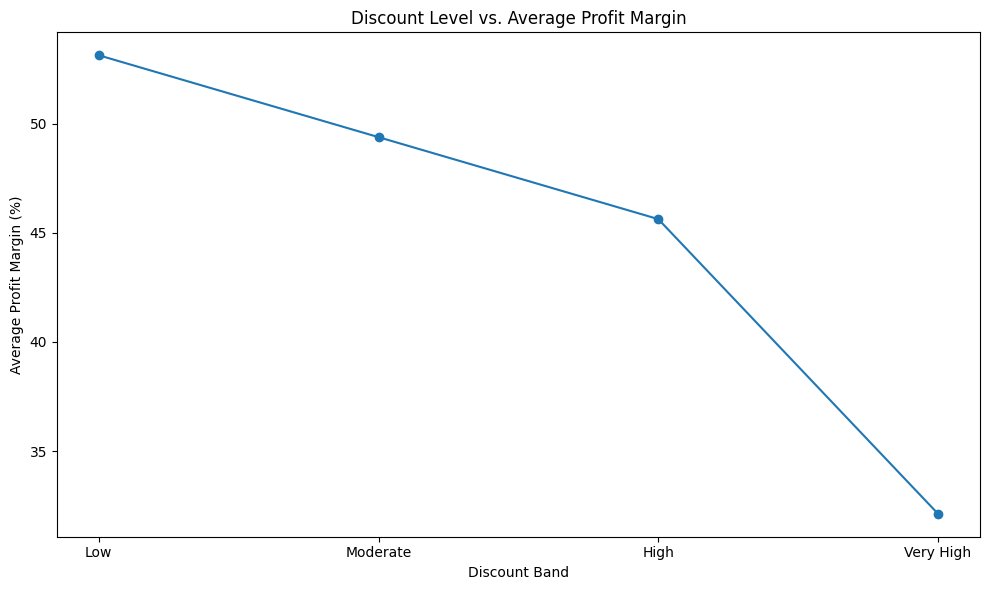

In [55]:
plt.figure(figsize=(10, 6))

plt.plot(
    discount_analysis["discount_band"],
    discount_analysis["average_profit_margin"],
    marker="o")

plt.title("Discount Level vs. Average Profit Margin")
plt.xlabel("Discount Band")
plt.ylabel("Average Profit Margin (%)")

plt.tight_layout()
plt.show()

In [56]:
marketing_analysis = sales.groupby("marketing_channel").agg(
    orders=("order_id", "nunique"),
    customers=("customer_id", "nunique"),
    average_order_value=("net_sales", "mean"),
    average_profit_margin=("profit_margin_percentage", "mean")
).reset_index()

In [57]:
marketing_analysis = marketing_analysis.sort_values(
    "average_order_value",
    ascending=False)

marketing_analysis

,marketing_channel,orders,customers,average_order_value,average_profit_margin
0,Affiliate,6848,5981,1289.120879,45.110101
4,Google Ads,20633,13988,1286.317377,44.958546
2,Email Marketing,11218,9022,1285.473920,44.963173
6,Organic Search,27742,16778,1285.351073,45.065275
8,TikTok,5437,4888,1283.833743,45.144740
3,Facebook Ads,16651,12173,1283.554748,44.893224
7,Referral,11191,9058,1281.576696,45.218780
5,Instagram,13801,10563,1280.809105,45.074363
9,YouTube,4080,3765,1274.017321,45.347689
1,Direct,20515,13963,1273.111651,45.190918


In [58]:
customer_channel_count = sales.groupby("customer_id")[
    "marketing_channel"
].nunique()

print(
    "Customers with 1 marketing channel:",
    (customer_channel_count == 1).sum())

print(
    "Customers with multiple marketing channels:",
    (customer_channel_count > 1).sum())

Customers with 1 marketing channel: 799
Customers with multiple marketing channels: 24112


In [59]:
sales_sorted = sales.sort_values(
    ["customer_id", "order_date", "order_id"])

customer_acquisition = sales_sorted.drop_duplicates(
    "customer_id",
    keep="first"
)[[
    "customer_id",
    "marketing_channel"
]].rename(
    columns={"marketing_channel": "acquisition_channel"})

In [60]:
customer_acquisition.head(10)

,customer_id,acquisition_channel
116414,CUST-000001,TikTok
44854,CUST-000002,Email Marketing
20250,CUST-000003,Instagram
13974,CUST-000004,Affiliate
24359,CUST-000005,Referral
3507,CUST-000006,Email Marketing
67421,CUST-000007,Organic Search
110457,CUST-000008,Direct
68952,CUST-000009,Google Ads
31439,CUST-000010,Email Marketing


In [61]:
customer_acquisition = customer_acquisition.reset_index(drop=True)

customer_acquisition.head(10)

,customer_id,acquisition_channel
0,CUST-000001,TikTok
1,CUST-000002,Email Marketing
2,CUST-000003,Instagram
3,CUST-000004,Affiliate
4,CUST-000005,Referral
5,CUST-000006,Email Marketing
6,CUST-000007,Organic Search
7,CUST-000008,Direct
8,CUST-000009,Google Ads
9,CUST-000010,Email Marketing


In [62]:
customer_value_marketing = customer_summary.merge(
    customer_acquisition,
    on="customer_id",
    how="left")

In [63]:
print("Customers:", customer_value_marketing["customer_id"].nunique())
print("Missing acquisition channels:", customer_value_marketing["acquisition_channel"].isna().sum())

Customers: 24911
Missing acquisition channels: 0


In [64]:
acquisition_analysis = customer_value_marketing.groupby("acquisition_channel"
).agg(
    customers=("customer_id", "nunique"),
    average_orders=("orders", "mean"),
    average_customer_value=("monetary", "mean"),
    average_profit_margin=("profit", "sum")
).reset_index()

In [65]:
customer_value_marketing["customer_profit_margin"] = (
    customer_value_marketing["profit"]
    / customer_value_marketing["revenue"]
    * 100)

In [66]:
customer_value_marketing["R_score"] = customer_value_marketing["R_score"].astype(int)
customer_value_marketing["F_score"] = customer_value_marketing["F_score"].astype(int)
customer_value_marketing["M_score"] = customer_value_marketing["M_score"].astype(int)

In [67]:
acquisition_analysis = customer_value_marketing.groupby("acquisition_channel"
).agg(
    customers=("customer_id", "nunique"),
    average_orders=("orders", "mean"),
    average_recency_score=("R_score", "mean"),
    average_frequency_score=("F_score", "mean"),
    average_monetary_score=("M_score", "mean"),
    average_profit_margin=("customer_profit_margin", "mean")
).reset_index()

In [68]:
acquisition_analysis = acquisition_analysis.sort_values(
    "average_monetary_score",
    ascending=False)

acquisition_analysis

,acquisition_channel,customers,average_orders,average_recency_score,average_frequency_score,average_monetary_score,average_profit_margin
0,Affiliate,1235,5.583806,3.063968,3.036437,3.034818,43.591527
6,Organic Search,5012,5.523144,3.003791,2.985036,3.023743,43.484584
3,Facebook Ads,2947,5.566678,2.975229,3.011537,3.015270,43.426634
9,YouTube,745,5.606711,3.038926,3.038926,3.014765,43.671156
1,Direct,3741,5.587276,2.996525,3.039027,3.005613,43.560877
2,Email Marketing,2045,5.591687,3.014670,3.026406,2.998533,43.393336
7,Referral,2067,5.513788,2.995162,2.973391,2.989357,43.534995
4,Google Ads,3719,5.524603,3.023662,2.985749,2.982522,43.265892
5,Instagram,2384,5.505453,2.956795,2.962668,2.965604,43.486944
8,TikTok,1016,5.463583,3.056102,2.960630,2.930118,43.741610


In [69]:
delivery_returns = sales[
    sales["delivery_status"] != "Cancelled"
].copy()

In [70]:
delivery_returns["is_returned"] = (
    delivery_returns["return_status"] == "Returned"
).astype(int)

In [71]:
pd.crosstab(
    sales["delivery_status"],
    sales["return_status"],
    dropna=False
)

return_status,Returned,NaN
delivery_status,,
Cancelled,9462,15095
Delayed,0,16886
Early,0,9757
On Time,0,86916


In [72]:
delivery_analysis = sales[
    sales["delivery_days"].notna()
].copy()

delivery_analysis["delivery_variance"] = (
    delivery_analysis["delivery_days"]
    - delivery_analysis["estimated_delivery_days"])

In [73]:
delivery_summary = delivery_analysis.groupby("delivery_status").agg(
    orders=("order_id", "nunique"),
    average_delivery_days=("delivery_days", "mean"),
    average_estimated_days=("estimated_delivery_days", "mean"),
    average_delivery_variance=("delivery_variance", "mean")
).reset_index()

delivery_summary

,delivery_status,orders,average_delivery_days,average_estimated_days,average_delivery_variance
0,Delayed,16886,6.832702,4.305223,2.527478
1,Early,9757,2.929794,4.290766,-1.360972
2,On Time,86916,4.298553,4.298553,0.000000


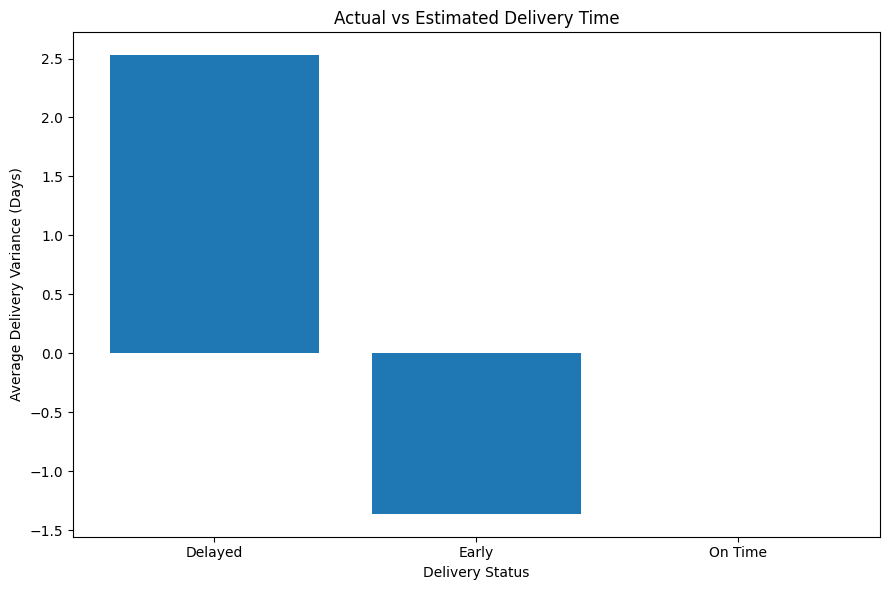

In [74]:
plt.figure(figsize=(9, 6))

plt.bar(
    delivery_summary["delivery_status"],
    delivery_summary["average_delivery_variance"])

plt.title("Actual vs Estimated Delivery Time")
plt.xlabel("Delivery Status")
plt.ylabel("Average Delivery Variance (Days)")

plt.tight_layout()
plt.show()